# 이진 분류 실험 ⑫ — 다운샘플링 유무 비교 (Multi-FraudGT)
서비스(dev) 의 이진 모델 **Multi-FraudGT** 를 내 base 피처로 학습시켜, 학습 target 을 다운샘플링했을 때와 안 했을 때를 비교한다. HI-Large, 시드 1개.
다운샘플링은 **loss 에만** 적용한다 — 그래프 · 이웃은 전체 거래 그대로 두고, 손실에 넣을 학습 target 만 바꾼다.

| 조건 | 학습 target | 만드는 곳 |
|---|---|---|
| `none` | 학습 구간 전체 102,336,629건 | — |
| `random_r10` | 양성 전부 + 날마다 양성 × 10 무작위 (1,217,381건) | `11_downsample_select.ipynb` |
| `hard_r10` | 양성 전부 + 정상 예산의 50% 를 세탁 계좌 주변 정상으로 | 〃 |
| `strata_r10` | 양성 전부 + 날짜 · 금액 · 은행 간 3축 층화 | 〃 (`features_train` 필요) |

select 파일이 없는 조건은 건너뛴다. 나중에 만들어 다시 돌리면 끝난 조건은 건너뛰고 새 조건만 돈다.

## 확정 설정 (2026-11-22)
코드는 `bc_fraudgt.py`. 모델 · 학습 방법은 dev(= 공식 FraudGT Large-HI Multi 설정), 평가는 09 를 따른다

| 항목 | 값 | 출처 |
|---|---|---|
| 모델 | Multi-FraudGT 만 (HGB · fusion 제외). reverse MP · port · ego ID 전부 사용 | 지정 |
| 피처 | 09 의 base 20열 + port 2열. 결제방식 · 절대 시각 없음 | 지정 |
| 분할 | 학습 08-08 ~ 10-02 · 검증 10-03 ~ 10-16 · 테스트 10-17 ~ 10-30 | 지정 |
| 이웃 | 2홉 [50, 50], 방향별 (균등 · 비복원) | 지정 |
| 손실 가중 | 양성 6.27, 모든 조건 동일 | 지정 |
| 적용 위치 | loss 만 | 지정 |
| 노드 입력 | [상수 1, ego ID] 2열 (계좌 피처 14열은 엣지에 실려 있다) | 09 |
| port 넣는 방식 | 2열을 `to` · `rev_to` 양쪽에 (rev_to 는 교환), z-norm — Multi-GNN 공식 방식 | 09 |
| 모델 크기 | hidden 64 · head 8 · 2층 · attention dropout 0.2 · 분류 헤드 192 → 192 → 1 | dev |
| readout | 학습 official (이웃 샘플에 뽑힌 target 만 손실에), 평가 all_targets | dev |
| 손실 형태 | 출력 1개 + BCE 양성 가중 | dev |
| 최적화 | AdamW · lr 0.001 · weight decay 1e-5 · warmup 5 에폭 + cosine · grad clip 1.0 · 8 배치 누적 후 1 step | dev |
| 배치 · 에폭 | 2048, 에폭 = 256 배치 | dev = 09 |
| 최대 에폭 | 200, 조기 종료 없음. cosine 은 250 기준 (200 에폭 시점 학습률 ≈ 최댓값의 10%). 필요하면 나중에 250 까지 이어 돈다 | 확정 |
| 검증 | 4 에폭마다와 마지막 에폭. 09 고정 표본 (양성 전부 + 날짜별 정상 2%, 가중) | 09 |
| 체크포인트 선택 | 검증 AP 최고 | 09 |
| 테스트 | 구간 전체 추론. `전체` 와 `Reinvestment 제외` 를 같이 본다 | 09 |
| 추론 배치 | 2048 (공유 서브그래프라 배치 크기가 점수에 영향) | dev = 09 |
| 시드 | 42 하나 | 확정 |

**읽을 때 주의**
- 같은 6.27 이어도 손실에서 양성이 차지하는 비중이 `none` 약 0.7%, r10 약 39% 로 다르다 (3 절 표). 조건 간 차이에는 "정상을 덜 본다" 와 "양성 쪽으로 균형이 옮겨간다" 가 같이 들어 있다
- 정상을 줄이면 확률이 부풀려진다 → **F1@0.5 · ECE 는 조건 간에 비교하지 않는다.** AP 와 예산 컷(상위 0.1% · 1%) 지표로 본다
- 시드가 하나다. 예전 샘플링 실험에서 시드만 바꿔도 검증 AP 가 0.04 ~ 0.06 흔들렸다. 그보다 작은 차이는 판단하지 않는다
- 에폭당 target 은 52만 건이다. `none` 은 200 에폭에 학습 구간을 약 1.0바퀴, r10 은 약 86바퀴 돈다 (250 에폭이면 1.3바퀴 · 107바퀴)
- **250 까지 이어 돌리기**: 설정 셀의 `max_epochs` 만 250 으로 바꿔 다시 실행한다. 조건마다 201 에폭부터 이어 가고, 최고 체크포인트가 바뀐 조건만 테스트를 다시 한다. 학습률 곡선은 처음부터 250 을 돌린 것과 같다 (배치 순서만 다르다)

**속도 설정** (결과에 영향 없음 — 2026-11-22 시간 점검: 배치당 0.875초 중 GPU 0.722초 · 이웃 샘플링 0.149초)
- `checkpoint_layers=False` : activation checkpointing 을 끈다 (GPU 0.722 → 0.558초, 최대 메모리 16.2 → 21.9GB). 학습 중 메모리가 모자라면 자동으로 켜고 계속 간다
- `num_workers=2` : 이웃 샘플링을 CPU 워커가 미리 해 둔다 (무작위 이웃 추출의 난수 순서만 달라진다). 워커에서 문제가 나면 0 으로 둔다

**실행 순서**: `SMOKE = True` 로 끝까지 한 번 (에러 · 에폭당 시간 · GPU 메모리 확인. 5.1 절 시간 점검도 이때만 돈다) → `SMOKE = False`. 끊기면 0 ~ 4 절을 다시 돌리고 6 절을 실행하면 그 에폭부터 이어진다

## 0. 작업 준비

In [1]:
import sys, json, time, gc, dataclasses
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.append(str(Path.cwd()))
import bc_lib as B
import bc_fraudgt as FG
L = B.L

In [2]:
# ---- 확정 설정 (머리말 표). 여기 값을 바꾸면 다른 실험이다 ------------------------------
DATASET = 'HI-Large'
SMOKE = True                      # True: 에폭 2 · 에폭당 8 배치 · 검증/테스트 일부만으로 끝까지 한 번. 결과는 downsample_fraudgt_smoke2/ 에 따로
RUN_NAME = 'downsample_fraudgt' + ('_smoke2' if SMOKE else '')    # smoke2: 워커 · checkpointing 끈 설정으로 다시 확인 (예전 smoke 결과는 _smoke/ 에 그대로)
cfg = B.Config(dataset=DATASET, smoke=SMOKE, num_neighbors=[50, 50], batch_size=2048, eval_batch_size=2048,
               iter_per_epoch=256, eval_period=4, seed=42, use_reverse_mp=True, use_ports=True, use_ego=True,
               num_workers=2)                                                            # 이웃 샘플링을 하는 CPU 워커 수 (속도용. 0 = 메인 프로세스에서 직접)
fcfg = FG.FGTConfig(hidden=64, heads=8, layers=2, attention_dropout=0.2,                # 모델 (dev = 공식)
                    pos_weight=6.27,                                                     # BCE 양성 가중
                    base_lr=0.001, weight_decay=1e-5, warmup_epochs=5,                   # AdamW + warmup
                    max_epochs=200, schedule_epochs=250,                                 # 200 에폭에서 멈춘다. cosine 은 250 기준 — max_epochs 만 250 으로 올려 다시 돌리면 이어 간다
                    batch_accumulation=8, gradient_clip=1.0,
                    train_readout='official',                                            # 평가는 항상 all_targets
                    checkpoint_layers=False)                                             # 속도용 (결과 영향 없음). 학습 중 GPU 메모리가 모자라면 자동으로 켜진다
if SMOKE:
    fcfg = dataclasses.replace(fcfg, max_epochs=2)                                       # cfg 쪽은 Config 가 smoke 값으로 바꾼다 (에폭당 8 배치, 검증 매 에폭)
B.seed_all(cfg.seed)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR = cfg.out_dir(RUN_NAME)

# 조건 이름 → select 폴더 이름 (None = 샘플링 없음)
CONDS = {'none': None, 'random_r10': 'random_r10', 'hard_r10': 'hard_r10', 'strata_r10': 'strata_r10_day-amount-cross_bank'}

# 피처 — 09 와 같은 22열 (base 20 + port 2)
AMOUNT_FEATURES = ['amount_received', 'received_currency']
PAIR_FEATURES = ['pair_prior_count', 'pair_gap_minutes', 'pair_count_1h', 'reverse_history_count']
ACT_FEATURES = ['src_out_1h', 'dst_in_1h']
HIST_FEATURES = ['src_hist_out', 'src_hist_uniq_out', 'src_active_days', 'src_rate_vs_prior', 'src_minute_burst', 'src_gap_minutes',
                 'dst_hist_in', 'dst_hist_uniq_in', 'dst_active_days', 'dst_rate_vs_prior', 'dst_minute_burst', 'dst_gap_minutes']
BASE_FEATURES = AMOUNT_FEATURES + PAIR_FEATURES + ACT_FEATURES + HIST_FEATURES
GNN_FEATURES = BASE_FEATURES + B.PORT_FEATURES
PORT_COLS = [GNN_FEATURES.index('in_port'), GNN_FEATURES.index('out_port')]
PATHS = {'pair': cfg.feat_dir / 'pair_history.parquet', 'act': cfg.feat_dir / 'account_activity.parquet', 'hist': cfg.feat_dir / 'account_history.parquet'}
FEAT_PATH = cfg.feat_dir / 'feat16_gnn_structure.npy'         # 09 가 만든 22열 z-norm 행렬 (float16, 약 7.9GB). 있으면 그대로 쓴다
REUSE_FEAT = FEAT_PATH.exists()
if not REUSE_FEAT:
    for p_ in PATHS.values():
        assert p_.exists(), f'앞 단계 parquet 이 없다: {p_}'

print(f'device {DEVICE} · 출력 {OUT_DIR}')
print(f'이웃 {cfg.num_neighbors} · 배치 {cfg.batch_size} · 에폭당 {cfg.iter_per_epoch} 배치 · 검증 {cfg.eval_period} 에폭마다 · 시드 {cfg.seed} · 샘플링 워커 {cfg.num_workers}')
print(f'피처 행렬 {"재사용: " + FEAT_PATH.name if REUSE_FEAT else "새로 만든다"}')
pd.Series(dataclasses.asdict(fcfg), name='FGTConfig').to_frame()

device cuda · 출력 /home/aml/workspace/money_laundry_ai_/code/binary_classification/results/HI-Large/downsample_fraudgt_smoke2
이웃 [50, 50] · 배치 2048 · 에폭당 8 배치 · 검증 1 에폭마다 · 시드 42 · 샘플링 워커 2
피처 행렬 재사용: feat16_gnn_structure.npy


,FGTConfig
hidden,64
heads,8
layers,2
attention_dropout,0.2
pos_weight,6.27
base_lr,0.001
weight_decay,0.00001
warmup_epochs,5
max_epochs,2
schedule_epochs,250


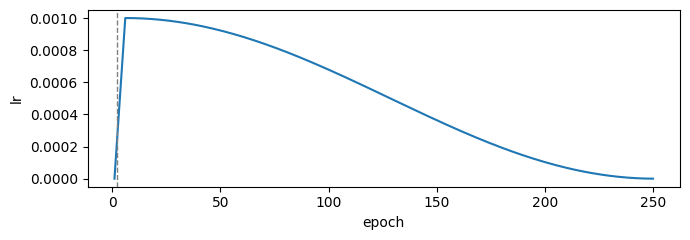

2 에폭의 학습률 2.00e-04 (최댓값 1e-03 의 20%)


In [3]:
# 학습률 곡선 — warmup 5 에폭 뒤 cosine 으로 schedule_epochs 에 0. 세로선 = 이번에 멈추는 에폭(max_epochs)
ep = np.arange(1, fcfg.schedule_epochs + 1)
fig, ax = plt.subplots(figsize=(7, 2.5)); ax.plot(ep, [fcfg.learning_rate(e) for e in ep]); ax.axvline(fcfg.max_epochs, color='gray', ls='--', lw=1)
ax.set_xlabel('epoch'); ax.set_ylabel('lr'); plt.tight_layout(); plt.show()
print(f'{fcfg.max_epochs} 에폭의 학습률 {fcfg.learning_rate(fcfg.max_epochs):.2e} (최댓값 {fcfg.base_lr:.0e} 의 {fcfg.learning_rate(fcfg.max_epochs) / fcfg.base_lr:.0%})')

## 1. 데이터 준비 — 거래 전체 + 피처
09 와 같다. 09 가 만든 22열 행렬(`feat16_gnn_structure.npy`) 이 있으면 그대로 읽고, 없으면 같은 방법으로 만든다

In [4]:
con = L.connect(threads=8, memory='12GB')
currency_codes, format_codes = B.code_tables(con, cfg)
PORTS_PATH = B.ensure_ports(con, cfg)               # features_ports/ports.parquet — 있으면 건너뜀

In [5]:
con.close(); con = L.connect(threads=8, memory='3GB')
con.register('currency_codes', currency_codes); con.register('format_codes', format_codes)   # 코드표는 연결마다 다시 등록
tx = B.load_tx_lowmem(con, cfg, port_path=None if REUSE_FEAT else PORTS_PATH)
if not REUSE_FEAT:                                                         # 09 의 1 절과 같은 순서
    tx = B.attach_parquet(tx, PATHS['pair'], PAIR_FEATURES, dtype=np.float16)
    tx = B.attach_parquet(tx, PATHS['act'], ACT_FEATURES, dtype=np.float16)
    tx = B.attach_parquet(tx, PATHS['hist'], HIST_FEATURES, dtype=np.float16)
B.trim('(tx 로드 후)'); tx.shape

RSS 7.6 GB (tx 로드 후)


(179702079, 9)

## 2. z-norm (학습 구간 통계) + 검증 · 테스트 표본

In [6]:
in_train = B.window_mask(tx, cfg.train_window)
if REUSE_FEAT:
    feat_z = np.load(FEAT_PATH, mmap_mode='r')
    assert feat_z.shape == (len(tx), len(GNN_FEATURES)) and feat_z.dtype == np.float16, f'{FEAT_PATH.name} 모양이 다르다: {feat_z.shape} — 지우고 다시 실행하면 새로 만든다'
    tx.drop(columns=[c for c in B.BASIC_EDGE_FEATURES if c in tx.columns], inplace=True)
    probe = np.flatnonzero(in_train)[::500]                                # 학습 구간 행을 500건마다 하나씩 — z-norm 된 값이 맞는지 눈으로 확인 (평균 0 · 표준편차 1 근처)
    chk = np.asarray(feat_z[probe], dtype=np.float32); assert np.isfinite(chk).all(), '피처 행렬에 nan/inf'
    znorm_table = pd.DataFrame({'feature': GNN_FEATURES, 'mean(train 표본)': chk.mean(0), 'std(train 표본)': chk.std(0)}); del chk, probe
else:
    feat_z, znorm_table = B.znorm_features(tx, GNN_FEATURES, in_train, out_path=FEAT_PATH)   # tx 에서 피처 열은 떨어짐
B.trim('(z-norm 후)'); znorm_table.round(3)

RSS 10.1 GB (z-norm 후)


,feature,mean(train 표본),std(train 표본)
0,amount_received,0.001,0.477
1,received_currency,-0.004,1.000
2,pair_prior_count,0.002,0.997
3,pair_gap_minutes,0.000,0.999
4,pair_count_1h,-0.000,1.000
5,reverse_history_count,0.000,1.002
6,src_out_1h,0.000,1.001
7,dst_in_1h,-0.002,0.996
8,src_hist_out,0.000,1.001
9,src_hist_uniq_out,-0.000,1.001


In [7]:
for name, w in [('train', cfg.train_window), ('val', cfg.val_window), ('test', cfg.test_window)]:
    m = B.window_mask(tx, w); assert m.sum() > 0, f'{name} 구간 {w} 에 거래가 없음'
    print(f'{name:5s} {w}  거래 {m.sum():>12,}  세탁 {tx.loc[m, "y"].sum():>8,}  비율 {tx.loc[m, "y"].mean()*100:.3f}%')

train 2022-08-08:2022-10-02  거래  102,336,629  세탁  110,671  비율 0.108%
val   2022-10-03:2022-10-16  거래   24,413,046  세탁   33,795  비율 0.138%
test  2022-10-17:2022-10-30  거래   26,808,230  세탁   34,460  비율 0.129%


In [8]:
val_df = B.val_sample(con, cfg.val_window, cfg.val_neg_rate)        # 검증: 양성 전부 + 정상 2% 가중 표본 (지금까지와 같은 파일)
test_df = B.test_full(con, cfg.test_window)                         # 테스트: 구간 전체
con.close()
if cfg.smoke:                                                        # 에러 잡기용: 검증 1/20, 테스트 앞 20만 건만
    val_df = val_df.iloc[::20].reset_index(drop=True); test_df = test_df.iloc[:200_000].reset_index(drop=True)

all_edge_ids = tx['edge_id'].to_numpy()
val_idx = B.rows_of(all_edge_ids, val_df['edge_id'].to_numpy()); test_idx = B.rows_of(all_edge_ids, test_df['edge_id'].to_numpy())
assert (tx['y'].to_numpy()[val_idx] == val_df['y'].to_numpy()).all()
val_df.shape, test_df.shape

((26070, 7), (200000, 5))

## 3. 학습 target — 조건마다
`none` 은 학습 구간 전체, 나머지는 `select/<이름>/selected.parquet` 의 `edge_id`. 그래프는 조건과 무관하게 같다 (loss 샘플링)
- `양성 손실 비중` = 양성 수 × 6.27 ÷ (정상 수 + 양성 수 × 6.27). 가중은 같아도 조건마다 이 값이 다르다
- `N 에폭 바퀴 수` = 최대 에폭 × 256 × 2048 ÷ target 수

In [9]:
y_all = tx['y'].to_numpy(); n_pos_train = int(y_all[in_train].sum())
TRAIN_ROWS, rows_tbl = {}, []
for name, sel_name in CONDS.items():
    if sel_name is None:
        rows = np.flatnonzero(in_train)
    else:
        p_ = L.SAMPLING / 'select' / sel_name / 'selected.parquet'
        if not p_.exists():
            print(f'[{name}] select 없음 — 건너뜀: {p_}'); continue
        sel = pd.read_parquet(p_, columns=['edge_id', 'y'])
        rows = B.rows_of(all_edge_ids, sel['edge_id'].to_numpy())
        assert in_train[rows].all(), f'{name}: 학습 구간 밖의 거래가 있다'
        assert (y_all[rows] == sel['y'].to_numpy()).all(), f'{name}: 라벨이 tx 와 다르다'
        assert int(y_all[rows].sum()) == n_pos_train, f'{name}: 양성이 전부 들어 있지 않다'
        assert len(np.unique(rows)) == len(rows), f'{name}: 중복 거래'
        del sel
    TRAIN_ROWS[name] = rows
    pos = int(y_all[rows].sum()); neg = len(rows) - pos
    rows_tbl.append({'조건': name, 'target': len(rows), '양성': pos, '정상': neg, '정상:양성': round(neg / pos, 1),
                     '양성 손실 비중': round(pos * fcfg.pos_weight / (neg + pos * fcfg.pos_weight), 4),
                     f'{fcfg.max_epochs} 에폭 바퀴 수': round(fcfg.max_epochs * cfg.iter_per_epoch * cfg.batch_size / len(rows), 1)})
assert 'none' in TRAIN_ROWS
del all_edge_ids, y_all
pd.DataFrame(rows_tbl).set_index('조건')

,target,양성,정상,정상:양성,양성 손실 비중,2 에폭 바퀴 수
조건,,,,,,
none,102336629,110671,102225958,923.7,0.0067,0.0
random_r10,1217381,110671,1106710,10.0,0.3854,0.0
hard_r10,1217381,110671,1106710,10.0,0.3854,0.0
strata_r10,1217374,110671,1106703,10.0,0.3854,0.0


## 4. 그래프 저장소 — 피처 행렬은 GPU 로
09 와 같다 (22열 float16 ≈ 7.9GB 를 GPU 에). 저장소만 `FGTStore` — 배치에 target 의 tx 행 번호를 같이 싣는다 (official readout 용)

In [10]:
store = FG.FGTStore(tx, feat_z, cfg, train_rows=TRAIN_ROWS['none'], val_idx=val_idx, test_idx=test_idx, port_cols=PORT_COLS)
del tx, feat_z; B.trim('(tx, feat_z 삭제 후)')
store.features_to_gpu(DEVICE)
if DEVICE.type == 'cuda':
    print(f'GPU 할당 {torch.cuda.memory_allocated() / 1e9:.1f} GB / 전체 {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
B.trim('(피처 GPU 이동 후)'); store.edge_dim

[15:20:31] 피처 행렬 memmap(기존) (179702079, 22)
[15:20:31] 간선 수 (정방향): 학습까지 117,269,636  검증까지 141,682,682  테스트까지 168,490,912
RSS 9.4 GB (tx, feat_z 삭제 후)


/home/aml/workspace/money_laundry_ai_/code/binary_classification/bc_lib.py:535: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  out[a:a + chunk] = torch.from_numpy(np.ascontiguousarray(feat[a:a + chunk], dtype=np.float16)).to(device)


[15:20:33] 피처 행렬 → cuda float16 (179702079, 22) (7.9GB, 1s)
GPU 할당 7.9 GB / 전체 25.3 GB
RSS 5.0 GB (피처 GPU 이동 후)


22

## 5. 배치 확인 — 조건마다 배치 하나
학습 전에 배치가 생각대로 나오는지 본다. 조건마다 학습 그래프를 한 번 올린다 (그래프는 같고 target 만 다르다)

| 열 | 기대 |
|---|---|
| `양성` | `none` 은 배치 2048 중 2건 안팎, r10 은 186건 안팎 |
| `to 간선` · `rev_to 간선` | 조건끼리 비슷 (그래프가 같다). 둘 다 0 보다 커야 한다 |
| `ego 합` | target 양끝 계좌 수 (4096 이하) |
| `official 채점` | 샘플에 뽑힌 target 수. dev 실험의 coverage 는 약 34% 였다 |
| `official = all_targets` | 뽑힌 target 은 두 readout 의 점수가 같아야 한다 (True) |
| `GPU 최대` | 학습 한 스텝(순전파 + 역전파) 의 최대 할당. GPU 전체 메모리보다 넉넉히 작아야 한다 |

In [11]:
TO, REV = B.TO, B.REV
rows = []
for name in TRAIN_ROWS:
    store.set_train_rows(TRAIN_ROWS[name])
    batch = next(iter(store.use('train'))).to(DEVICE)
    torch.manual_seed(0); model = FG.make_fraudgt(store.edge_dim, fcfg).to(DEVICE)
    args = (batch['node'].x, [batch[TO].edge_index, batch[REV].edge_index], [batch[TO].edge_attr, batch[REV].edge_attr], batch[TO].edge_label_index, batch.target_attr)
    pos = FG.target_positions(batch[TO].orig.long(), batch.target_rows)
    model.eval()
    with torch.no_grad():
        lo, so = model(*args, pos, 'official'); la, _ = model(*args, pos, 'all_targets')
    same = bool(torch.allclose(lo, la[so], atol=1e-4)) if len(lo) else None
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    model.train(); t0 = time.time()
    logits, labels, n = FG.forward_batch(model, batch, DEVICE, fcfg.train_readout)
    (FG.weighted_bce(logits, labels, fcfg.pos_weight).sum() / max(len(logits), 1)).backward()
    step_sec = time.time() - t0
    rows.append({'조건': name, 'target': n, '양성': int(batch[TO].edge_label.sum()), '노드': batch['node'].num_nodes,
                 'to 간선': batch[TO].num_edges, 'rev_to 간선': batch[REV].num_edges, 'ego 합': int(batch['node'].x[:, 1].sum()),
                 'official 채점': len(lo), 'coverage': round(len(lo) / n, 3), 'official = all_targets': same, 'all_targets 채점': len(la),
                 'port 절댓값 합': round(float(batch[TO].edge_attr[:, PORT_COLS].abs().sum()), 1),
                 'GPU 최대(GB)': round(torch.cuda.max_memory_allocated() / 1e9, 1) if DEVICE.type == 'cuda' else None, '스텝(초)': round(step_sec, 2),
                 '파라미터': sum(p.numel() for p in model.parameters())})
    del model, batch, args, logits, labels, lo, la; gc.collect(); torch.cuda.empty_cache()
check = pd.DataFrame(rows).set_index('조건'); check

RSS 5.0 GB 


/home/aml/workspace/.venv-exp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[15:20:43] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  9s
RSS 10.0 GB 
RSS 5.8 GB 
[15:21:10] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  8s
RSS 10.6 GB 
RSS 5.8 GB 
[15:21:32] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  8s
RSS 10.6 GB 
RSS 5.8 GB 
[15:21:55] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  8s
RSS 10.6 GB 


,target,양성,노드,to 간선,rev_to 간선,ego 합,official 채점,coverage,official = all_targets,all_targets 채점,port 절댓값 합,GPU 최대(GB),스텝(초),파라미터
조건,,,,,,,,,,,,,,
none,2048,1,123297,786461,732041,3784,795,0.388,True,2048,356139.5,21.1,0.29,226113
random_r10,2048,173,131128,822395,769449,3837,765,0.374,True,2048,367622.2,21.8,0.20,226113
hard_r10,2048,204,123949,779425,722226,3645,772,0.377,True,2048,371558.2,21.0,0.19,226113
strata_r10,2048,189,132119,818925,764459,3839,779,0.380,True,2048,371072.2,21.7,0.20,226113


In [12]:
# 기대값과 다르면 여기서 멈춘다
for name in check.index:
    c = check.loc[name]
    assert c['all_targets 채점'] == c['target'], f'{name}: all_targets 인데 빠진 target 이 있다'
    assert c['to 간선'] > 0 and c['rev_to 간선'] > 0, f'{name}: 역방향 또는 정방향 간선이 없다'
    assert 0 < c['ego 합'] <= 2 * c['target'] and c['port 절댓값 합'] > 0, f'{name}: ego · port 입력이 비었다'
    assert c['official 채점'] > 0 and c['official = all_targets'], f'{name}: official readout 이 all_targets 와 다르다'
print('배치 확인 통과')

배치 확인 통과


### 5.1 시간 점검 — 배치 하나가 어디서 시간을 쓰나 (smoke 에서만)
학습은 안 한다. 20 배치를 뽑아 순전파 + 역전파까지 하고 구간별 시간을 잰다. checkpointing 을 켠 것 / 끈 것 두 줄

| 열 | 뜻 |
|---|---|
| `배치 대기(초)` | 다음 배치를 받을 때까지 메인 프로세스가 기다린 시간. 워커가 미리 뽑아 두면 0 에 가깝고, `num_workers=0` 이면 이웃 샘플링 시간 그대로다 |
| `피처 붙이기(초)` | GPU 의 피처 행렬에서 엣지 피처를 꺼내는 시간 |
| `GPU 순전파+역전파(초)` | 모델 계산. GPU 작업이 끝날 때까지 기다려서 잰 값 |
| `GPU 최대(GB)` | 그 20 배치 동안의 최대 할당. 끈 행이 GPU 전체 메모리에 가까우면 본 실행에서 OOM 이 날 수 있다 (나면 자동으로 checkpointing 을 켠다) |

2026-11-22 측정 (워커 0): 켬 0.875초 (대기 0.149 · GPU 0.722 · 16.2GB), 끔 0.711초 (대기 0.148 · GPU 0.558 · 21.9GB)

In [13]:
RUN_PROFILE = SMOKE                 # 본 실행에서는 건너뛴다 (재고 싶으면 True)
N_BATCH = 20


def sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()        # GPU 작업이 실제로 끝날 때까지 기다린다 (안 기다리면 GPU 시간이 짧게 재진다)


class Timed:
    # 메인 프로세스 쪽 배치 변환(피처 붙이기) 에 걸린 시간을 따로 잰다
    def __init__(self, fn):
        self.fn, self.sec = fn, 0.0

    def __call__(self, batch):
        t = time.perf_counter(); out = self.fn(batch); sync(); self.sec += time.perf_counter() - t
        return out


prof = None
if RUN_PROFILE:
    cond = 'random_r10' if 'random_r10' in TRAIN_ROWS else 'none'
    store.set_train_rows(TRAIN_ROWS[cond])
    loader = store.use('train'); timed = Timed(loader.transform); loader.transform = timed
    rows = []
    for ck in (True, False):
        fc = dataclasses.replace(fcfg, checkpoint_layers=ck); torch.manual_seed(0)
        model = FG.make_fraudgt(store.edge_dim, fc).to(DEVICE).train(); opt = FG.make_optimizer(model, fc)
        if DEVICE.type == 'cuda':
            torch.cuda.reset_peak_memory_stats()
        it = iter(loader); next(it); sync()                        # 첫 배치는 준비 시간이 섞여서 버린다
        timed.sec, t_load, t_gpu, edges, oom = 0.0, 0.0, 0.0, 0, False
        try:
            for _ in range(N_BATCH):
                t = time.perf_counter(); batch = next(it); sync(); t_load += time.perf_counter() - t
                t = time.perf_counter()
                logits, labels, n = FG.forward_batch(model, batch, DEVICE, fc.train_readout)
                (FG.weighted_bce(logits, labels, fc.pos_weight).sum() / max(len(logits), 1)).backward()
                opt.zero_grad(set_to_none=True); sync(); t_gpu += time.perf_counter() - t
                edges += batch[B.TO].num_edges + batch[B.REV].num_edges
                del batch, logits, labels
        except torch.cuda.OutOfMemoryError:
            oom = True
        rows.append({'checkpoint': ck, '배치 대기(초)': (t_load - timed.sec) / N_BATCH, '피처 붙이기(초)': timed.sec / N_BATCH, 'GPU 순전파+역전파(초)': t_gpu / N_BATCH,
                     '배치당 합계(초)': (t_load + t_gpu) / N_BATCH, '에폭(256배치) 예상(초)': (t_load + t_gpu) / N_BATCH * 256,
                     'GPU 최대(GB)': torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == 'cuda' else None, '배치당 간선': edges // N_BATCH, 'OOM': oom})
        del model, opt, it; gc.collect(); torch.cuda.empty_cache()
    loader.transform = timed.fn; del loader
    store.set_train_rows(TRAIN_ROWS['none'])                       # 그래프 · loader 를 내려 둔다
    import os; print(f'조건 {cond} · CPU 코어 {os.cpu_count()} · 샘플링 워커 {cfg.num_workers}')
    prof = pd.DataFrame(rows).set_index('checkpoint').round(3)
prof

RSS 5.8 GB 
[15:22:17] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  8s
RSS 10.6 GB 
조건 random_r10 · CPU 코어 8 · 샘플링 워커 2


,배치 대기(초),피처 붙이기(초),GPU 순전파+역전파(초),배치당 합계(초),에폭(256배치) 예상(초),GPU 최대(GB),배치당 간선,OOM
checkpoint,,,,,,,,
True,0.005,0.017,0.733,0.755,193.23,16.117,1569870,False
False,0.005,0.019,0.556,0.580,148.57,21.838,1566095,False


## 6. 학습 · 테스트 — 조건마다
조건 하나 = `max_epochs` 에폭 학습(검증 AP 최고 체크포인트 저장) → 테스트 구간 전체 추론 → 결과 저장
- **끝난 단계는 건너뛴다**: `<조건>_done.json` 에 적힌 에폭 수가 `max_epochs` 이상이면 학습을, 그 체크포인트의 `<조건>_test_scores.parquet` 가 있으면 테스트를 건너뛴다
- **더 돌리기**: `max_epochs` 를 늘려(250 까지) 다시 실행하면 끝난 조건도 마지막 에폭 다음부터 이어 간다. 최고 체크포인트가 바뀌면 테스트를 다시 한다
- **끊기면 이어 간다**: 에폭마다 `<조건>_last.pt` 를 남긴다. 커널이 죽으면 0 ~ 4 절을 다시 돌리고 이 절을 실행하면 그 에폭부터 이어진다 (설정이 바뀌었으면 멈춘다)
- 진행 중인 기록은 `<조건>_history.csv` 에 에폭마다 쌓인다. `cov` = 그 에폭에 손실에 들어간 target 비율 (official readout)
- 돌릴 조건을 고르려면 `RUN` 을 바꾼다 (예: `RUN = ['none', 'random_r10']`)

In [ ]:
RUN = list(TRAIN_ROWS)             # select 가 있는 조건 전부. 순서대로 돈다
results_path = OUT_DIR / 'results.json'
results = json.loads(results_path.read_text(encoding='utf-8'))['results'] if results_path.exists() else {}
FEATURES_INFO = dict(gnn=GNN_FEATURES, conditions=CONDS, fraudgt=dataclasses.asdict(fcfg))


def run_cond(name):
    store.set_train_rows(TRAIN_ROWS[name])
    if FG.is_done(name, OUT_DIR, fcfg):
        print(f'[{name}] {fcfg.max_epochs} 에폭까지 학습 끝난 것 있음 — 건너뜀')
    else:
        B.log(f'[{name}] 학습 시작  target {len(TRAIN_ROWS[name]):,}')
        model, _ = FG.train_fraudgt(name, store, cfg, fcfg, val_df, OUT_DIR, DEVICE, results)
        del model; gc.collect(); torch.cuda.empty_cache()
    if not FG.needs_test(name, OUT_DIR, results):
        print(f'[{name}] 테스트 점수 있음 — 건너뜀')
    else:
        FG.test_fraudgt(name, store, cfg, fcfg, test_df, OUT_DIR, DEVICE, results)
    return B.save_results(OUT_DIR, cfg, results, features=FEATURES_INFO)     # 조건 하나 끝날 때마다 저장


for name in RUN:
    compare = run_cond(name)
compare

[15:22:57] [none] 학습 시작  target 102,336,629
RSS 5.7 GB 
[15:23:06] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  9s
RSS 10.6 GB 


RSS 5.9 GB 
[15:23:37] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  10s
RSS 11.7 GB 
epoch   1  lr 1.00e-09  loss 0.6535  cov 0.37  AP 0.0084  F1 0.0297  recall@1% 0.0767  (학습 5s + 검증 27s)
RSS 5.9 GB 
[15:24:03] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  9s
RSS 10.8 GB 


RSS 5.9 GB 
[15:24:32] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  9s
RSS 11.8 GB 
epoch   2  lr 2.00e-04  loss 0.6537  cov 0.38  AP 0.0076  F1 0.0274  recall@1% 0.0889  (학습 5s + 검증 25s)
RSS 6.0 GB 
[15:24:59] 그래프 to 168,490,912 + rev_to 168,490,912 간선 (정렬됨)  11s
RSS 12.9 GB 
none (1분) {'AP': 0.0044, 'F1': 0.019, 'precision': 0.0099, 'recall': 0.2366, 'threshold': 0.4983, 'recall_at_1pct': 0.1221, 'unmatched_recall_at_1pct': 0.1757, 'ECE': 0.4546, 'F1_at_0.5': 0.017}
[15:25:42] [random_r10] 학습 시작  target 1,217,381
RSS 6.0 GB 
[15:25:51] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  9s
RSS 10.8 GB 


RSS 5.9 GB 
[15:26:19] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  10s
RSS 11.8 GB 
epoch   1  lr 1.00e-09  loss 1.2658  cov 0.38  AP 0.0084  F1 0.0299  recall@1% 0.0767  (학습 5s + 검증 27s)
RSS 6.0 GB 
[15:26:44] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  9s
RSS 10.8 GB 


RSS 6.0 GB 
[15:27:12] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  10s
RSS 11.8 GB 
epoch   2  lr 2.00e-04  loss 1.2278  cov 0.39  AP 0.0145  F1 0.0462  recall@1% 0.0883  (학습 5s + 검증 27s)
RSS 6.0 GB 
[15:27:40] 그래프 to 168,490,912 + rev_to 168,490,912 간선 (정렬됨)  12s
RSS 12.9 GB 
random_r10 (1분) {'AP': 0.0075, 'F1': 0.0325, 'precision': 0.0169, 'recall': 0.3893, 'threshold': 0.5231, 'recall_at_1pct': 0.1985, 'unmatched_recall_at_1pct': 0.2297, 'ECE': 0.4619, 'F1_at_0.5': 0.0119}
[15:28:23] [hard_r10] 학습 시작  target 1,217,381
RSS 5.9 GB 
[15:28:32] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  9s
RSS 10.8 GB 


RSS 6.0 GB 
[15:29:00] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  11s
RSS 11.8 GB 
epoch   1  lr 1.00e-09  loss 1.2484  cov 0.39  AP 0.0084  F1 0.0299  recall@1% 0.0767  (학습 5s + 검증 27s)
RSS 6.0 GB 
[15:29:25] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  9s
RSS 10.8 GB 


RSS 6.0 GB 
[15:29:52] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  10s
RSS 11.8 GB 
epoch   2  lr 2.00e-04  loss 1.2028  cov 0.38  AP 0.0144  F1 0.0454  recall@1% 0.0877  (학습 5s + 검증 26s)
RSS 6.0 GB 
[15:30:20] 그래프 to 168,490,912 + rev_to 168,490,912 간선 (정렬됨)  12s
RSS 12.9 GB 
hard_r10 (1분) {'AP': 0.0075, 'F1': 0.0323, 'precision': 0.0168, 'recall': 0.4046, 'threshold': 0.5198, 'recall_at_1pct': 0.1985, 'unmatched_recall_at_1pct': 0.2297, 'ECE': 0.4599, 'F1_at_0.5': 0.0135}
[15:31:03] [strata_r10] 학습 시작  target 1,217,374
RSS 6.0 GB 
[15:31:12] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  9s
RSS 10.8 GB 


RSS 6.0 GB 
[15:31:40] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  11s
RSS 11.8 GB 
epoch   1  lr 1.00e-09  loss 1.2494  cov 0.39  AP 0.0084  F1 0.0297  recall@1% 0.0761  (학습 5s + 검증 27s)
RSS 6.0 GB 
[15:32:05] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  9s
RSS 10.8 GB 


RSS 6.0 GB 
[15:32:33] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  10s
RSS 11.8 GB 
epoch   2  lr 2.00e-04  loss 1.2467  cov 0.39  AP 0.0146  F1 0.0458  recall@1% 0.0912  (학습 5s + 검증 26s)
RSS 6.0 GB 
[15:33:01] 그래프 to 168,490,912 + rev_to 168,490,912 간선 (정렬됨)  12s
RSS 12.9 GB 


# 결과 — 저장된 점수 파일만으로 돌아간다
커널을 새로 켰으면 **0 절(설정 셀 2개)** 만 돌리고 여기부터. 재료는 `results/HI-Large/downsample_fraudgt/`

## 7. 전체 지표
- `test−val` : 검증 → 테스트 하락폭
- `F1@0.5` 는 참고로만 둔다 (정상을 줄인 조건은 확률이 부풀려져 0.5 의 뜻이 다르다)
- 참고 행 `gine_09` : 09 의 `rev_port_ego` (같은 22열 입력, GINe, 이웃 [100, 100]) 점수 파일이 있으면 같이 본다

In [ ]:
ORDER = [c for c in CONDS if (OUT_DIR / f'{c}_test_scores.parquet').exists()]
assert ORDER, '테스트 점수가 없다 — 6 절을 먼저 돌린다'
REF_PATHS = {} if SMOKE else {'gine_09': Path.cwd() / 'results' / DATASET / 'gnn_structure' / 'rev_port_ego_test_scores.parquet'}
REF_PATHS = {k: p_ for k, p_ in REF_PATHS.items() if p_.exists()}
cmp = pd.read_csv(OUT_DIR / 'compare.csv', index_col=[0, 1])
res = json.loads((OUT_DIR / 'results.json').read_text(encoding='utf-8'))['results']
tbl = pd.DataFrame({c: {'val_AP': cmp.loc[(c, 'val'), 'AP'], 'test_AP': cmp.loc[(c, 'test'), 'AP'], 'F1(최적 임계값)': cmp.loc[(c, 'test'), 'F1'],
                        'F1@0.5 (참고)': cmp.loc[(c, 'test'), 'F1_at_0.5'], 'recall@1%': cmp.loc[(c, 'test'), 'recall_at_1pct'],
                        'unmatched@1%': cmp.loc[(c, 'test'), 'unmatched_recall_at_1pct']} for c in ORDER}).T
tbl.insert(2, 'test−val', tbl['test_AP'] - tbl['val_AP'])
tbl.to_csv(OUT_DIR / 'summary.csv', encoding='utf-8-sig')
display(tbl.round(4))
if len(ORDER) > 1 and 'none' in ORDER:
    print('none 대비 차이 (양수 = 다운샘플링이 높다)'); display((tbl.drop(index='none') - tbl.loc['none']).round(4))

In [ ]:
# 학습 기록 — 최고 에폭, 학습 시간, 에폭당 시간, official readout coverage
pd.DataFrame({c: {k: res[c].get(k) for k in ('best_epoch', 'epochs_run', 'train_sec', 'epoch_sec', 'coverage', 'n_params', 'gpu_peak_gb')} for c in ORDER if c in res}).T

In [ ]:
# 학습 곡선 — 검증 AP 와 학습 손실. 조건 간 차이가 한 조건 안의 출렁임보다 작으면 "차이 없음" 으로 읽는다
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5)); swing = {}
for c in ORDER:
    h = pd.read_csv(OUT_DIR / f'{c}_history.csv'); v = h.dropna(subset=['AP'])
    axes[0].plot(v['epoch'], v['AP'], marker='.', ms=4, lw=1, label=c); axes[1].plot(h['epoch'], h['train_loss'], lw=1, label=c)
    late = v[v['epoch'] > v['epoch'].max() / 2]['AP']                    # 후반부 검증 AP 의 출렁임
    swing[c] = {'최고 AP': v['AP'].max(), '최고 에폭': int(v.loc[v['AP'].idxmax(), 'epoch']), '후반부 평균': late.mean(), '후반부 표준편차': late.std(), '마지막 AP': v['AP'].iloc[-1]}
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('val AP'); axes[0].legend(); axes[1].set_xlabel('epoch'); axes[1].set_ylabel('train loss (조건마다 양성 비중이 달라 크기는 비교 불가)'); axes[1].set_yscale('log')
plt.tight_layout(); plt.savefig(OUT_DIR / 'curves.png', dpi=120); plt.show()
pd.DataFrame(swing).T.round(4)

## 8. 패턴 기준 지표 — 09 와 같은 계산
무패턴 양성은 정답도 오답도 아닌 것으로 두고 뺀다. 알림 = 테스트 전체 점수 상위 0.1% · 1% (조건마다 알림 수가 같다). 결제방식은 평가에서만 쓴다

In [ ]:
ALL = ORDER + list(REF_PATHS)
scores = {c: B.load_scores(OUT_DIR / f'{c}_test_scores.parquet') for c in ORDER}
scores.update({k: B.load_scores(p_) for k, p_ in REF_PATHS.items()})
ref_ids = scores[ORDER[0]]['edge_id'].to_numpy()
for c in ALL:
    assert np.array_equal(scores[c]['edge_id'].to_numpy(), ref_ids), f'{c} 점수의 행 순서가 다르다'
lab = B.pattern_array(scores[ORDER[0]])                       # 'NORMAL' · 'UNMATCHED' · 패턴 이름
is_normal, is_un = lab == 'NORMAL', lab == 'UNMATCHED'
is_pat = ~is_normal & ~is_un

con = L.connect(threads=8, memory='6GB')
FORMATS = [r[0] for r in con.execute(f"SELECT DISTINCT payment_format FROM read_parquet({L.q(cfg.tx_path)}) ORDER BY 1").fetchall()]
T_A, T_B = L.parse_window(cfg.test_window)
case = ' '.join(f'WHEN {L.q(f)} THEN {k}' for k, f in enumerate(FORMATS))
meta = con.execute(f"""
    SELECT edge_id, datediff('day', DATE {L.q(T_A)}, day)::SMALLINT AS d, (CASE payment_format {case} END)::TINYINT AS fmt, src::INT AS src, dst::INT AS dst
    FROM read_parquet({L.q(cfg.tx_path)}) WHERE day BETWEEN DATE {L.q(T_A)} AND DATE {L.q(T_B)} ORDER BY edge_id""").fetchnumpy()
con.close()
pos = np.minimum(np.searchsorted(meta['edge_id'], ref_ids), len(meta['edge_id']) - 1)
assert (meta['edge_id'][pos] == ref_ids).all()
meta = {k: np.asarray(v)[pos] for k, v in meta.items()}        # 점수 행 순서에 맞춘다 (smoke 처럼 테스트 일부만 있을 때도)
is_ach = meta['fmt'] == FORMATS.index('ACH')
is_reinv = meta['fmt'] == FORMATS.index('Reinvestment') if 'Reinvestment' in FORMATS else np.zeros(len(ref_ids), bool)
last_day = meta['d'] == meta['d'].max()
print(f'테스트 {len(lab):,}건 · 패턴 {int(is_pat.sum()):,} · 무패턴 {int(is_un.sum()):,} · 정상 {int(is_normal.sum()):,} · Reinvestment {int(is_reinv.sum()):,}')

In [ ]:
from sklearn.metrics import average_precision_score


def eval_pop(s, keep):
    # keep 안에서만 평가. 무패턴은 패턴 지표에서 정답도 오답도 아닌 것으로 둔다 (09 의 7 절 · 10.7 절과 같은 계산)
    s_, pat_, un_, nor_, ach_ = s[keep], is_pat[keep], is_un[keep], is_normal[keep], is_ach[keep]
    r = {'거래': int(keep.sum()), '패턴': int(pat_.sum()), 'AP': average_precision_score(~nor_, s_), 'AP 패턴': average_precision_score(pat_[~un_], s_[~un_])}
    for budget in (0.001, 0.01):
        k = f'{budget * 100:g}%'; hit = s_ >= np.quantile(s_, 1 - budget)
        tp, fp = int((hit & pat_).sum()), int((hit & nor_).sum())
        r.update({f'알림@{k}': int(hit.sum()), f'패턴R@{k}': tp / max(int(pat_.sum()), 1), f'패턴P@{k}': tp / max(tp + fp, 1), f'무패턴R@{k}': (hit & un_).sum() / max(int(un_.sum()), 1),
                  f'정상오탐@{k}': fp, f'비ACH알림@{k}': int((hit & ~ach_).sum())})
    return r


POPS = {'전체': np.ones(len(ref_ids), bool), 'Reinvestment 제외': ~is_reinv, '마지막 날 제외': ~last_day}
POPS = {p: keep for p, keep in POPS.items() if keep.any()}      # 비는 평가 대상은 뺀다 (smoke 는 테스트 앞 20만 건이 전부 첫날이라 '마지막 날 제외' 가 0건)
t0 = time.time()
excl = pd.DataFrame({(p, c): eval_pop(scores[c]['score'].to_numpy(), keep) for p, keep in POPS.items() for c in ALL}).T
excl.index.names = ['평가 대상', '조건']; excl.to_csv(OUT_DIR / 'pattern_metrics.csv', encoding='utf-8-sig')
print(f'{time.time() - t0:.0f}s')
SHOW = ['거래', '패턴', 'AP', 'AP 패턴', '패턴R@0.1%', '패턴P@0.1%', '정상오탐@0.1%', '비ACH알림@0.1%', '무패턴R@0.1%', '패턴R@1%', '무패턴R@1%']
for p in POPS:
    print(f'--- {p}'); display(excl.loc[p][SHOW].astype(float).round(4))

In [ ]:
# 지표별로 나란히 — 행 = 조건, 열 = 평가 대상. 그리고 none 대비 차이
for col in ('AP', 'AP 패턴', '패턴R@0.1%', '패턴P@0.1%', '무패턴R@1%'):
    wide = excl[col].unstack(0).loc[ALL, list(POPS)].astype(float)
    print(f'--- {col}'); display(wide.round(4))
    if 'none' in ORDER and len(ORDER) > 1:
        print(f'    none 대비 차이'); display((wide.loc[[c for c in ORDER if c != 'none']] - wide.loc['none']).round(4))

## 9. 패턴 유형별 recall
상위 0.1% · 1% 컷. 다운샘플링으로 특정 패턴이 떨어지거나 오르는지 본다 (`UNMATCHED` = 무패턴 세탁)

In [ ]:
pat = pd.concat([B.pattern_recall(scores[c]).assign(cond=c) for c in ALL])
pat.to_csv(OUT_DIR / 'analysis_pattern.csv', encoding='utf-8-sig')
order_p = [p for p in B.PATTERN_ORDER + ['ALL'] if p in pat.index]
n_by_pattern = pat[pat.cond == ORDER[0]]['n'].astype(int)
for col in ('r@0.1%', 'r@1%'):
    wide = pat.reset_index().pivot(index='pattern_type', columns='cond', values=col).loc[order_p, ALL]
    print(f'--- {col}'); display(wide.round(4).assign(n=n_by_pattern))
    if 'none' in ORDER and len(ORDER) > 1:
        print(f'    none 대비 차이'); display(wide[[c for c in ORDER if c != 'none']].sub(wide['none'], axis=0).round(4).assign(n=n_by_pattern))

## 10. 읽는 법
- **먼저 7 절의 학습 곡선**: 한 조건 안에서 검증 AP 가 출렁이는 폭(후반부 표준편차) 을 본다. 조건 간 차이가 그 폭 안이면 "차이 없음" 이다. 시드가 하나라는 것도 같이 적는다
- **최고 에폭**: 다운샘플링 조건은 같은 정상 거래를 여러 바퀴 돌기 때문에 일찍 최고점을 찍고 내려갈 수 있다. `none` 은 200 에폭에 1.0바퀴라 끝까지 오를 수 있다. 최고 에폭이 마지막 에폭 근처이고 검증 AP 가 끝까지 오르는 모양이면 예산이 모자란 것이다 → `max_epochs` 를 250 으로 올려 이어 돌린다
- **8 절**: `전체` 와 `Reinvestment 제외` 를 같이 본다 (09 에서 테스트 마지막 날의 Reinvestment 묶음이 지표를 좌우했다). 두 평가 대상에서 순서가 같으면 그 결론은 이 묶음과 무관하다
- **무패턴R**: 다운샘플링은 손실에서 양성 비중을 0.7% → 39% 로 올린다. 무패턴(양성의 41%) recall 이 달라지는지가 볼 만한 지점이다
- **차이가 났을 때**: 원인이 "정상을 덜 봐서" 인지 "양성 비중이 올라서" 인지는 이 실험만으로 못 가른다. r10 에 양성 가중 0.068 (= 6.27 × 10 ÷ 924, `none` 과 같은 목적함수) 을 준 조건을 추가하면 갈린다
- **참고 행 `gine_09`**: 입력은 같지만 모델(GINe) · 이웃 수([100, 100]) · 학습 방법이 다르다. 다운샘플링 비교와는 별개의 참고값이다